# DOSAGE Dataset – Filtering Demo

In [1]:
import pandas as pd
import numpy as np

In [9]:
# Load CSVs (replace with correct file paths if needed)
d_dose = pd.read_csv('d_dose.csv')
s_dose = pd.read_csv('s_dose.csv')
r_dose = pd.read_csv('r_dose.csv')

Filter Function: d_dose.csv (Disease-Specific Dosage)

In [10]:
def filter_d_dose(generic=None, disease=None, age=None, route=None, age_unit='y'):
    df = d_dose.copy()

    if generic:
        df = df[df['generic'].str.lower() == generic.lower()]
    if disease:
        df = df[df['disease'].str.lower() == disease.lower()]
    if route:
        df = df[df['route'].str.upper() == route.upper()]

    if age is not None:
        age_y = age if age_unit == 'y' else age / 12 if age_unit == 'm' else age / 365
        age_m = age if age_unit == 'm' else age * 12 if age_unit == 'y' else age / 30.44
        age_d = age if age_unit == 'd' else age * 365 if age_unit == 'y' else age * 30.44

        def age_match(row):
            for min_col, max_col, val in [
                ('min_age_y', 'max_age_y', age_y),
                ('min_age_m', 'max_age_m', age_m),
                ('min_age_d', 'max_age_d', age_d)
            ]:
                if pd.notna(row[min_col]) and pd.notna(row[max_col]):
                    if float(row[min_col]) <= val <= float(row[max_col]):
                        return True
            return False

        df = df[df.apply(age_match, axis=1)]

    return df.reset_index(drop=True)


In [11]:
# ▶ Example usage:
filter_d_dose(generic='Ampicillin', disease='Gastroenteritis', age=12, route='PO')

,generic,disease,min_age_d,max_age_d,min_age_m,max_age_m,min_age_y,max_age_y,min_weight,max_weight,...,min_dw_iu,max_dw_iu,limit_mg,limit_iu,min_dd_mg,max_dd_mg,min_dd_iu,max_dd_iu,route,Unnamed: 21
0,Ampicillin,Gastroenteritis,NaN,NaN,NaN,NaN,12.0,120.0,NaN,NaN,...,NaN,NaN,NaN,NaN,2000.0,2500.0,NaN,NaN,PO,NaN


Filter Function: s_dose.csv (Standard Dosage)

In [12]:
def filter_s_dose(generic=None, age=None, route=None, age_unit='y'):
    df = s_dose.copy()

    if generic:
        df = df[df['generic'].str.lower() == generic.lower()]
    if route:
        df = df[df['route'].str.upper() == route.upper()]

    if age is not None:
        age_y = age if age_unit == 'y' else age / 12 if age_unit == 'm' else age / 365
        age_m = age if age_unit == 'm' else age * 12 if age_unit == 'y' else age / 30.44
        age_d = age if age_unit == 'd' else age * 365 if age_unit == 'y' else age * 30.44

        def age_match(row):
            for min_col, max_col, val in [
                ('min_age_y', 'max_age_y', age_y),
                ('min_age_m', 'max_age_m', age_m),
                ('min_age_d', 'max_age_d', age_d)
            ]:
                if pd.notna(row[min_col]) and pd.notna(row[max_col]):
                    if float(row[min_col]) <= val <= float(row[max_col]):
                        return True
            return False

        df = df[df.apply(age_match, axis=1)]

    return df.reset_index(drop=True)


In [13]:
# ▶ Example usage:
filter_s_dose(generic='Ciprofloxacin', age=25, route='PO')

,generic,min_age_d,max_age_d,min_age_m,max_age_m,min_age_y,max_age_y,min_weight,max_weight,min_dw_mg,max_dw_mg,min_dw_iu,max_dw_iu,limit_mg,limit_iu,min_dd_mg,max_dd_mg,min_dd_iu,max_dd_iu,route
0,Ciprofloxacin,NaN,NaN,NaN,NaN,12.0,120.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.0,1500.0,NaN,NaN,PO


 Filter Function: r_dose.csv (Renal Adjustment Dosage)

In [14]:
def filter_r_dose(generic=None, disease=None, crcl=None, route=None, weight=None):
    df = r_dose.copy()

    if generic:
        df = df[df['generic'].str.lower() == generic.lower()]
    if disease:
        df = df[df['disease'].str.lower() == disease.lower()]
    if route:
        df = df[df['route'].str.upper() == route.upper()]
    if crcl is not None:
        df = df[
            (df['min_crcl'].astype(float) <= crcl) &
            (df['max_crcl'].astype(float) >= crcl)
        ]
    if weight is not None:
        df = df[
            ((df['min_weight'].isna()) | (df['min_weight'].astype(float) <= weight)) &
            ((df['max_weight'].isna()) | (df['max_weight'].astype(float) >= weight))
        ]

    return df.reset_index(drop=True)

In [15]:
# ▶ Example usage:
filter_r_dose(generic='Cefepime', crcl=25, route='IV')

,generic,disease,min_weight,max_weight,min_crcl,max_crcl,max_dd_mg,max_dw_mg,max_dd_iu,max_dw_iu,route,flag
0,Cefepime,NaN,NaN,NaN,10.0,29.0,2000.0,NaN,NaN,NaN,IV,NaN


## Association-rule transaction tables

Per-table pipeline: **drop junk columns** (`Unnamed:*`, empty `min_dose_dd_UNIT`), **dedupe rows**, **homogenize** strings (`generic`/`disease` title case, `route`/`flag` upper), **bin** numeric fields as items (`age_y=12-65`, `dw_mg=10-15`, `crcl=50-69`, …), then **long** (`transaction_id`, `item`) and **binary wide** matrices for Apriori / FP-Growth.

Outputs: `d_dose_clean`, `txn_long_d_dose`, `txn_matrix_d_dose` (and the same pattern for `s_dose`, `r_dose`).

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer
from IPython.display import display

def _fmt_num(x):
    if pd.isna(x):
        return None
    x = float(x)
    if x == int(x):
        return str(int(x))
    return f"{x:.6f}".rstrip("0").rstrip(".")


def range_item(prefix: str, min_val, max_val):
    if pd.isna(min_val) and pd.isna(max_val):
        return None
    if pd.notna(min_val) and pd.notna(max_val):
        lo, hi = _fmt_num(min_val), _fmt_num(max_val)
        return f"{prefix}={lo}-{hi}" if lo != hi else f"{prefix}={lo}"
    if pd.notna(min_val):
        return f"{prefix}>={_fmt_num(min_val)}"
    return f"{prefix}<={_fmt_num(max_val)}"


def clean_dosage_table(df: pd.DataFrame, *, verbose: bool = True) -> pd.DataFrame:
    out = df.copy()
    junk = [c for c in out.columns if str(c).startswith("Unnamed") or str(c).strip() == ""]
    out = out.drop(columns=junk, errors="ignore")
    if "min_dose_dd_UNIT" in out.columns and out["min_dose_dd_UNIT"].notna().sum() == 0:
        out = out.drop(columns=["min_dose_dd_UNIT"])
    for col in ("generic", "disease", "route", "flag"):
        if col not in out.columns:
            continue
        out[col] = out[col].astype("string").str.strip()
        if col == "route":
            out[col] = out[col].str.upper()
        elif col == "flag":
            out[col] = out[col].str.upper()
        else:
            out[col] = out[col].str.title()
    n_before = len(out)
    out = out.drop_duplicates().reset_index(drop=True)
    if verbose:
        print(f"  rows {n_before:,} → {len(out):,} after dedupe (dropped {n_before - len(out):,})")
    return out


def row_to_transaction_items(row: pd.Series) -> list[str]:
    items: list[str] = []
    if pd.notna(row.get("generic")) and str(row["generic"]).strip():
        items.append(f"generic={row['generic']}")
    if pd.notna(row.get("disease")) and str(row["disease"]).strip():
        items.append(f"disease={row['disease']}")
    if pd.notna(row.get("route")) and str(row["route"]).strip():
        items.append(f"route={row['route']}")
    if pd.notna(row.get("flag")) and str(row["flag"]).strip():
        items.append(f"flag={row['flag']}")
    for prefix, min_c, max_c in (
        ("age_d", "min_age_d", "max_age_d"),
        ("age_m", "min_age_m", "max_age_m"),
        ("age_y", "min_age_y", "max_age_y"),
        ("weight_kg", "min_weight", "max_weight"),
        ("crcl", "min_crcl", "max_crcl"),
    ):
        if min_c in row.index or max_c in row.index:
            it = range_item(prefix, row.get(min_c), row.get(max_c))
            if it:
                items.append(it)
    dose_pairs = (
        ("dw_mg", "min_dose_dw_mg", "max_dose_dw_mg"),
        ("dw_iu", "min_dose_dw_iu", "max_dose_dw_iu"),
        ("dd_mg", "min_dose_dd_mg", "max_dose_dd_mg"),
        ("dd_iu", "min_dose_dd_iu", "max_dose_dd_iu"),
        ("limit_mg", "limit_mg", "limit_mg"),
        ("limit_iu", "limit_iu", "limit_iu"),
        ("max_dd_mg", "max_dose_dd_mg", "max_dose_dd_mg"),
        ("max_dw_mg", "max_dose_dw_mg", "max_dose_dw_mg"),
        ("max_dd_iu", "max_dose_dd_iu", "max_dose_dd_iu"),
        ("max_dw_iu", "max_dose_dw_iu", "max_dose_dw_iu"),
    )
    emitted: set[str] = set()
    for prefix, min_c, max_c in dose_pairs:
        if min_c not in row.index and max_c not in row.index:
            continue
        it = range_item(prefix, row.get(min_c), row.get(max_c))
        if it and it not in emitted:
            items.append(it)
            emitted.add(it)
    return items


def build_transaction_tables(clean_df: pd.DataFrame, table_name: str):
    itemsets = [row_to_transaction_items(clean_df.loc[i]) for i in clean_df.index]
    txn_long_rows = []
    for tid, items in enumerate(itemsets):
        tx_id = f"{table_name}_{tid}"
        for it in items:
            txn_long_rows.append({"transaction_id": tx_id, "item": it})
    txn_long = pd.DataFrame(txn_long_rows)
    mlb = MultiLabelBinarizer()
    txn_matrix = pd.DataFrame(
        mlb.fit_transform(itemsets),
        columns=mlb.classes_,
        index=[f"{table_name}_{i}" for i in range(len(itemsets))],
    )
    txn_matrix.index.name = "transaction_id"
    meta = pd.DataFrame({"n_items": [len(s) for s in itemsets]}, index=txn_matrix.index)
    return txn_long, txn_matrix, meta


def summarize_transactions(name: str, clean_df, txn_long, txn_matrix, meta):
    print(f"\n=== {name} ===")
    print(f"  cleaned rows: {len(clean_df):,}")
    print(f"  transactions: {txn_matrix.shape[0]:,}")
    print(f"  unique items: {txn_matrix.shape[1]:,}")
    print(f"  avg items / transaction: {meta['n_items'].mean():.2f}")
    display(txn_long.head(12))
    n_show = min(8, txn_matrix.shape[1])
    display(txn_matrix.iloc[:5, :n_show])


print("Cleaning…")
d_dose_clean = clean_dosage_table(d_dose)
s_dose_clean = clean_dosage_table(s_dose)
r_dose_clean = clean_dosage_table(r_dose)

txn_long_d_dose, txn_matrix_d_dose, txn_meta_d_dose = build_transaction_tables(d_dose_clean, "d_dose")
txn_long_s_dose, txn_matrix_s_dose, txn_meta_s_dose = build_transaction_tables(s_dose_clean, "s_dose")
txn_long_r_dose, txn_matrix_r_dose, txn_meta_r_dose = build_transaction_tables(r_dose_clean, "r_dose")

summarize_transactions("d_dose (disease-specific)", d_dose_clean, txn_long_d_dose, txn_matrix_d_dose, txn_meta_d_dose)
summarize_transactions("s_dose (standard)", s_dose_clean, txn_long_s_dose, txn_matrix_s_dose, txn_meta_s_dose)
summarize_transactions("r_dose (renal)", r_dose_clean, txn_long_r_dose, txn_matrix_r_dose, txn_meta_r_dose)


## Transaction pipeline — cleaning QA & visuals

Summarizes **raw vs cleaned** row/column changes, **transaction shape**, sample **long-format** rows, and plots of **items per transaction** and **top frequent items**.

Cleaning changes (raw CSV → cleaned guideline table)


,rows_raw,rows_after_dedupe,duplicate_rows_removed,cols_raw,cols_clean,columns_removed,junk_or_empty_cols_dropped
table,,,,,,,
d_dose,3029,2953,76,22,21,1,Unnamed: 21
s_dose,288,288,0,20,20,0,—
r_dose,220,220,0,12,12,0,—


Transaction tables (cleaned row = one transaction)


,transactions,unique_items,long_format_rows,avg_items_per_txn,min_items_per_txn,max_items_per_txn,top_item,top_item_count,item_prefixes
table,,,,,,,,,
d_dose,2953,859,19410,6.57,1,10,route=IV,1241,"age_d, age_d>, age_m, age_m>, age_y, age_y<, d..."
s_dose,288,335,1626,5.65,5,8,route=PO,121,"age_d, age_d>, age_m, age_m>, age_y, age_y<, d..."
r_dose,220,254,1067,4.85,2,6,route=IV,113,"crcl, crcl<, crcl>, dd_iu<, dd_mg<, disease, d..."


Example transactions (long format collapsed to one row each)


,transaction_id,items,n_items
0,d_dose_0,generic=Amikacin | disease=Bacteremia | route=...,7
1,s_dose_0,generic=Amikacin | route=IM | age_y=12-65 | dw...,6
2,r_dose_0,generic=Amikacin | route=IV | crcl=70-89 | dw_...,5


Sample long-format rows (d_dose)


,transaction_id,item
0,d_dose_0,generic=Amikacin
1,d_dose_0,disease=Bacteremia
2,d_dose_0,route=IM
3,d_dose_0,age_y=12-65
4,d_dose_0,dw_mg=10-15
5,d_dose_0,limit_mg=1500
6,d_dose_0,max_dw_mg=15
7,d_dose_1,generic=Amikacin
8,d_dose_1,disease=Bacteremia
9,d_dose_1,route=IV


Sample binary matrix (d_dose, first 6 item columns)


,age_d=1-29,age_d=1-7,age_d=8-29,age_d>=29,age_d>=8,age_m=1-3
transaction_id,,,,,,
d_dose_0,0,0,0,0,0,0
d_dose_1,0,0,0,0,0,0
d_dose_2,0,0,0,0,0,0
d_dose_3,0,0,0,0,0,0
d_dose_4,0,0,0,0,0,0
d_dose_5,0,0,0,0,0,0


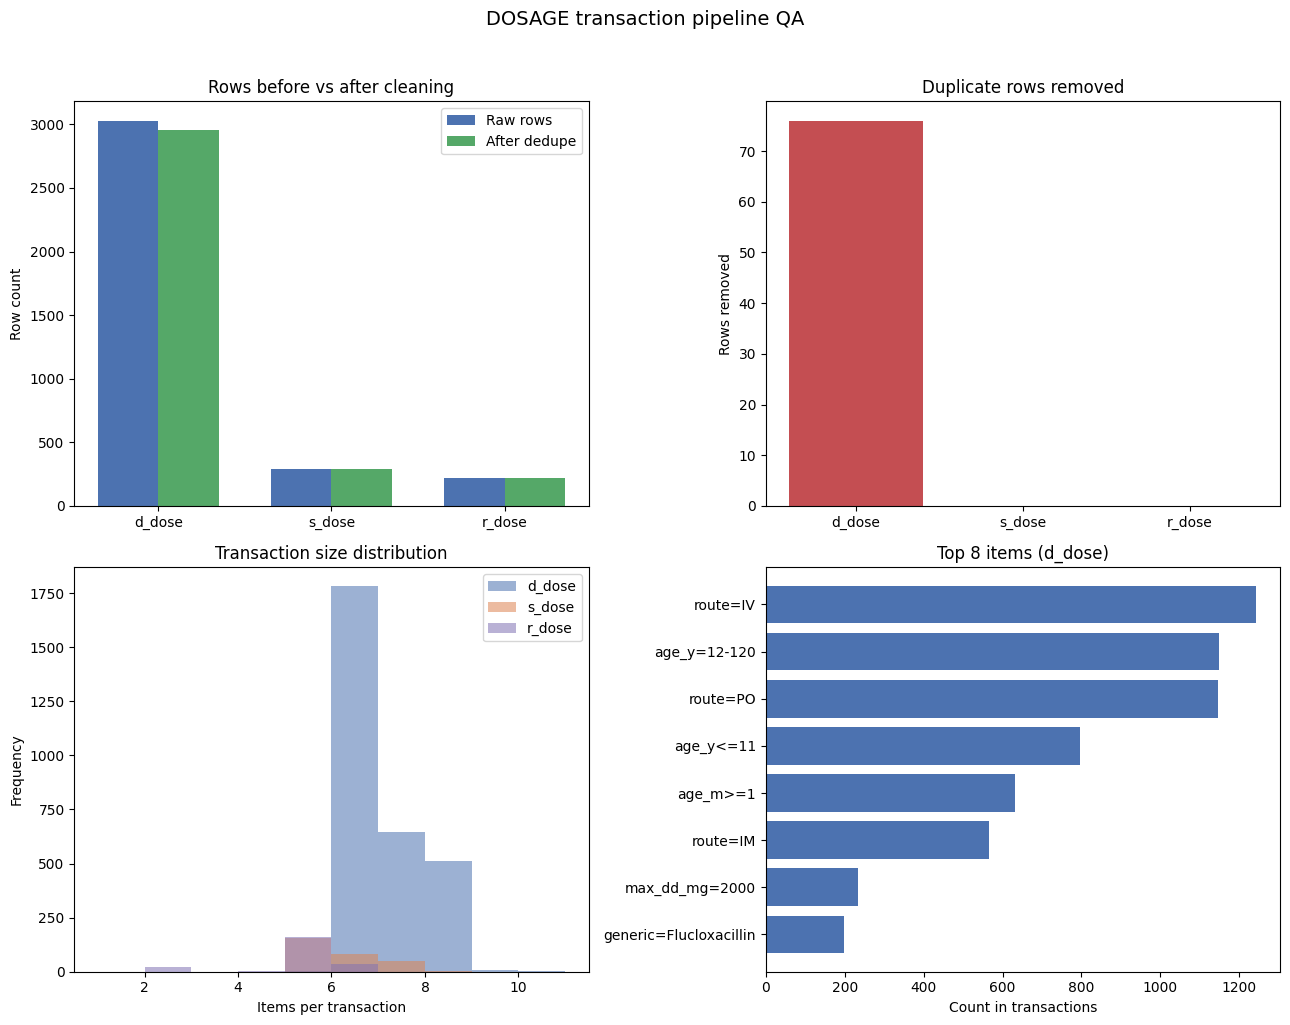

In [10]:
import matplotlib.pyplot as plt


def _junk_column_names(df: pd.DataFrame) -> list[str]:
    junk = [c for c in df.columns if str(c).startswith("Unnamed") or str(c).strip() == ""]
    if "min_dose_dd_UNIT" in df.columns and df["min_dose_dd_UNIT"].notna().sum() == 0:
        junk.append("min_dose_dd_UNIT")
    return junk


def build_cleaning_summary(raw: pd.DataFrame, clean: pd.DataFrame, table: str) -> dict:
    junk = _junk_column_names(raw)
    return {
        "table": table,
        "rows_raw": len(raw),
        "rows_after_dedupe": len(clean),
        "duplicate_rows_removed": len(raw) - raw.drop_duplicates().shape[0],
        "cols_raw": raw.shape[1],
        "cols_clean": clean.shape[1],
        "columns_removed": raw.shape[1] - clean.shape[1],
        "junk_or_empty_cols_dropped": ", ".join(junk) if junk else "—",
    }


def build_transaction_summary(
    table: str, txn_long: pd.DataFrame, txn_matrix: pd.DataFrame, meta: pd.DataFrame
) -> dict:
    item_counts = txn_long.groupby("item").size()
    prefixes = txn_long["item"].str.split("=", n=1).str[0]
    return {
        "table": table,
        "transactions": txn_matrix.shape[0],
        "unique_items": txn_matrix.shape[1],
        "long_format_rows": len(txn_long),
        "avg_items_per_txn": round(float(meta["n_items"].mean()), 2),
        "min_items_per_txn": int(meta["n_items"].min()),
        "max_items_per_txn": int(meta["n_items"].max()),
        "top_item": item_counts.idxmax(),
        "top_item_count": int(item_counts.max()),
        "item_prefixes": ", ".join(sorted(prefixes.unique())),
    }


def example_transaction(txn_long: pd.DataFrame, txn_id: str) -> pd.DataFrame:
    items = txn_long.loc[txn_long["transaction_id"] == txn_id, "item"].tolist()
    return pd.DataFrame({"transaction_id": [txn_id], "items": [" | ".join(items)], "n_items": [len(items)]})


cleaning_summary = pd.DataFrame(
    [
        build_cleaning_summary(d_dose, d_dose_clean, "d_dose"),
        build_cleaning_summary(s_dose, s_dose_clean, "s_dose"),
        build_cleaning_summary(r_dose, r_dose_clean, "r_dose"),
    ]
).set_index("table")

transaction_summary = pd.DataFrame(
    [
        build_transaction_summary("d_dose", txn_long_d_dose, txn_matrix_d_dose, txn_meta_d_dose),
        build_transaction_summary("s_dose", txn_long_s_dose, txn_matrix_s_dose, txn_meta_s_dose),
        build_transaction_summary("r_dose", txn_long_r_dose, txn_matrix_r_dose, txn_meta_r_dose),
    ]
).set_index("table")

print("Cleaning changes (raw CSV → cleaned guideline table)")
display(cleaning_summary)

print("Transaction tables (cleaned row = one transaction)")
display(transaction_summary)

print("Example transactions (long format collapsed to one row each)")
display(
    pd.concat(
        [
            example_transaction(txn_long_d_dose, "d_dose_0"),
            example_transaction(txn_long_s_dose, "s_dose_0"),
            example_transaction(txn_long_r_dose, "r_dose_0"),
        ],
        ignore_index=True,
    )
)

print("Sample long-format rows (d_dose)")
display(txn_long_d_dose.head(15))

print("Sample binary matrix (d_dose, first 6 item columns)")
display(txn_matrix_d_dose.iloc[:6, : min(6, txn_matrix_d_dose.shape[1])])

# --- plots ---
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

x = cleaning_summary.index
w = 0.35
ax = axes[0, 0]
ax.bar(np.arange(len(x)) - w / 2, cleaning_summary["rows_raw"], w, label="Raw rows", color="#4C72B0")
ax.bar(np.arange(len(x)) + w / 2, cleaning_summary["rows_after_dedupe"], w, label="After dedupe", color="#55A868")
ax.set_xticks(np.arange(len(x)), x)
ax.set_ylabel("Row count")
ax.set_title("Rows before vs after cleaning")
ax.legend()

ax = axes[0, 1]
ax.bar(x, cleaning_summary["duplicate_rows_removed"], color="#C44E52")
ax.set_ylabel("Rows removed")
ax.set_title("Duplicate rows removed")

ax = axes[1, 0]
for table, meta, color in (
    ("d_dose", txn_meta_d_dose, "#4C72B0"),
    ("s_dose", txn_meta_s_dose, "#DD8452"),
    ("r_dose", txn_meta_r_dose, "#8172B3"),
):
    ax.hist(meta["n_items"], bins=range(1, meta["n_items"].max() + 2), alpha=0.55, label=table, color=color)
ax.set_xlabel("Items per transaction")
ax.set_ylabel("Frequency")
ax.set_title("Transaction size distribution")
ax.legend()

ax = axes[1, 1]
top_n = 8
top_items = txn_long_d_dose["item"].value_counts().head(top_n).sort_values()
ax.barh(top_items.index, top_items.values, color="#4C72B0")
ax.set_xlabel("Count in transactions")
ax.set_title(f"Top {top_n} items (d_dose)")

fig.suptitle("DOSAGE transaction pipeline QA", fontsize=14, y=1.02)
fig.tight_layout()
plt.show()
